# Практическая работа № 6. Классификация текстов

ФИО: Эркинбеков Айман  
Вариант: B

Определяю тональность отзывов о фильмах: отзыв положительный или отрицательный. Сначала чищу текст, потом перевожу его в числа через TF-IDF и обучаю наивный байесовский классификатор.

In [1]:
import re
from functools import lru_cache
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from nltk.stem import SnowballStemmer

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

print("Библиотеки загружены")

Библиотеки загружены


## 1. Данные

Беру корпус отзывов `movie_reviews` из библиотеки NLTK. В нём 2000 отзывов на английском языке, по 1000 положительных и отрицательных. Копия лежит в `data/reviews.csv`.

In [2]:
DATA_PATH = Path("../data/reviews.csv")

if not DATA_PATH.exists():
    DATA_PATH = Path("practical-06/data/reviews.csv")

assert DATA_PATH.exists(), f"Файл не найден: {DATA_PATH}"

df = pd.read_csv(DATA_PATH)
df["label"] = (df["label"] == "pos").astype(int)

print("Размер таблицы:", df.shape)
display(df.head(3))

Размер таблицы: (2000, 2)


,text,label
0,"plot : two teen couples go to a church party ,...",0
1,the happy bastard's quick movie review \ndamn ...,0
2,it is movies like these that make a jaded movi...,0


In [3]:
print("Классы (0 = отрицательный, 1 = положительный):")
display(df["label"].value_counts().sort_index().to_frame("Количество"))

df["words_raw"] = df["text"].str.split().str.len()
print("Слов в отзыве до очистки:")
display(df["words_raw"].describe().round(0).to_frame("words_raw").T)

Классы (0 = отрицательный, 1 = положительный):


,Количество
label,
0,1000
1,1000


Слов в отзыве до очистки:


,count,mean,std,min,25%,50%,75%,max
words_raw,2000.0,746.0,328.0,17.0,527.0,696.0,904.0,2678.0


Классы поровну, по 1000 отзывов. Отзывы длинные: в среднем около 750 слов. Первые три строки имеют класс 0, потому что в корпусе сначала идут отрицательные отзывы.

## 2. Очистка текста

Функция `clean_text` делает по порядку: приводит текст к нижнему регистру, раскрывает сокращения вроде `didn't` в `did not`, убирает пунктуацию и цифры, делит текст на слова, убирает стоп-слова и приводит слова к основе через стеммер Snowball.

Отрицания `no`, `nor`, `not`, `never` и похожие слова из стоп-слов убираю из списка, то есть оставляю в тексте. В отзывах «not good» и «good» значат противоположное, и если выбросить `not`, смысл потеряется.

In [4]:
NEGATIONS = {"no", "nor", "not", "never", "none", "nobody", "nothing", "neither", "cannot"}
STOP_WORDS = set(ENGLISH_STOP_WORDS) - NEGATIONS

stemmer = SnowballStemmer("english")

@lru_cache(maxsize=None)
def stem(word):
    return stemmer.stem(word)

def clean_text(text):
    text = text.lower()
    text = text.replace("can't", "can not").replace("won't", "will not")
    text = re.sub(r"n't\b", " not", text)
    text = re.sub(r"[^a-z]+", " ", text)
    tokens = text.split()
    tokens = [t for t in tokens if t not in STOP_WORDS and len(t) > 1]
    tokens = [stem(t) for t in tokens]
    return " ".join(tokens)

example = "I didn't like this movie. The acting was bad, 2 hours wasted!"
print("До:   ", example)
print("После:", clean_text(example))

До:    I didn't like this movie. The acting was bad, 2 hours wasted!
После: did not like movi act bad hour wast


In [5]:
df["clean"] = df["text"].apply(clean_text)
df["words_clean"] = df["clean"].str.split().str.len()

print("Среднее число слов в отзыве:")
print("  до очистки:   ", round(df["words_raw"].mean()))
print("  после очистки:", round(df["words_clean"].mean()))

print("\nНачало первого отзыва до очистки:")
print(df.loc[0, "text"][:300])
print("\nТот же фрагмент после очистки:")
print(df.loc[0, "clean"][:300])

Среднее число слов в отзыве:
  до очистки:    746
  после очистки: 324

Начало первого отзыва до очистки:
plot : two teen couples go to a church party , drink and then drive . 
they get into an accident . 
one of the guys dies , but his girlfriend continues to see him in her life , and has nightmares . 
what's the deal ? 
watch the movie and " sorta " find out . . . 
critique : a mind-fuck movie for the

Тот же фрагмент после очистки:
plot teen coupl church parti drink drive accid guy die girlfriend continu life nightmar deal watch movi sorta critiqu mind fuck movi teen generat touch cool idea present bad packag make review harder write general applaud film attempt break mold mess head lost highway memento good bad way make type 


## 3. Разбиение

Сначала делю отзывы на обучающую и тестовую части. TF-IDF кладу в `Pipeline`, поэтому словарь и веса считаются только по обучающей части. Функция очистки ничему не обучается, поэтому применять её до разбиения безопасно.

In [6]:
X = df["clean"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Обучающая выборка:", X_train.shape[0])
print("Тестовая выборка: ", X_test.shape[0])
print("Доля положительных в train:", round(y_train.mean(), 3))
print("Доля положительных в test: ", round(y_test.mean(), 3))

Обучающая выборка: 1600
Тестовая выборка:  400
Доля положительных в train: 0.5
Доля положительных в test:  0.5


## 4. Ограничение словаря

`min_df` убирает слишком редкие слова, `max_df` убирает слова, которые есть почти в каждом отзыве. Перебираю несколько значений и сравниваю их по F1 на кросс-валидации. Делаю это только на обучающей части, тест не трогаю.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rows = []
for min_df in [1, 2, 5, 10]:
    for max_df in [1.0, 0.8, 0.5]:
        pipe = Pipeline([
            ("tfidf", TfidfVectorizer(min_df=min_df, max_df=max_df)),
            ("nb", MultinomialNB()),
        ])
        scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1")
        vocab_size = len(
            TfidfVectorizer(min_df=min_df, max_df=max_df).fit(X_train).vocabulary_
        )
        rows.append({
            "min_df": min_df,
            "max_df": max_df,
            "Слов в словаре": vocab_size,
            "F1 (CV)": scores.mean(),
        })

grid = pd.DataFrame(rows).sort_values(
    ["F1 (CV)", "Слов в словаре"], ascending=[False, True]
).reset_index(drop=True)

best_min_df = int(grid.loc[0, "min_df"])
best_max_df = float(grid.loc[0, "max_df"])

print("Выбрано: min_df =", best_min_df, ", max_df =", best_max_df)
display(grid.round(4))

Выбрано: min_df = 5 , max_df = 0.5


,min_df,max_df,Слов в словаре,F1 (CV)
0,5,0.5,8176,0.8193
1,5,0.8,8193,0.8186
2,10,0.5,5221,0.8175
3,5,1.0,8196,0.8170
4,10,1.0,5241,0.8169
5,10,0.8,5238,0.8153
6,2,0.8,14163,0.8122
7,2,1.0,14166,0.8115
8,1,0.5,22744,0.8109
9,2,0.5,14146,0.8107


Лучше всего получились `min_df=5` и `max_df=0.5`. Словарь сократился с 22 764 слов (без ограничений) до 8 176, а F1 на кросс-валидации немного выросла: с 0,808 до 0,819. Редкие слова почти не помогают, только раздувают словарь.

## 5. Модель и метрики

In [8]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(min_df=best_min_df, max_df=best_max_df)),
    ("nb", MultinomialNB()),
])
model.fit(X_train, y_train)

vectorizer = model.named_steps["tfidf"]
X_train_vec = vectorizer.transform(X_train)
print("Размерность признакового пространства (train):", X_train_vec.shape)
print("Слов в словаре:", len(vectorizer.vocabulary_))

pred = model.predict(X_test)

results = pd.DataFrame([{
    "Accuracy": accuracy_score(y_test, pred),
    "Precision": precision_score(y_test, pred),
    "Recall": recall_score(y_test, pred),
    "F1": f1_score(y_test, pred),
}])
display(results.round(3))

Размерность признакового пространства (train): (1600, 8176)
Слов в словаре: 8176


,Accuracy,Precision,Recall,F1
0,0.81,0.801,0.825,0.813


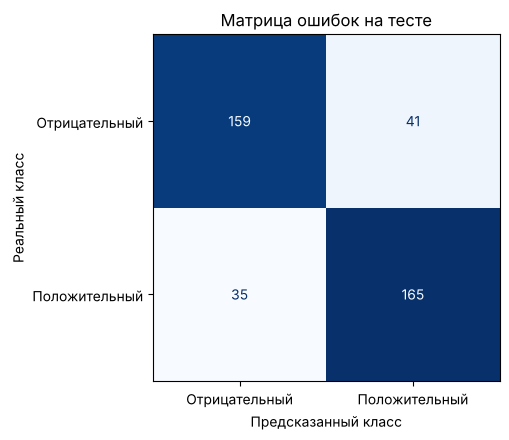

In [9]:
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred,
    display_labels=["Отрицательный", "Положительный"],
    cmap="Blues",
    colorbar=False,
    ax=ax,
)
ax.set_title("Матрица ошибок на тесте")
ax.set_xlabel("Предсказанный класс")
ax.set_ylabel("Реальный класс")
plt.tight_layout()
plt.show()

Размерность признакового пространства на обучении: 1600 отзывов на 8176 слов. На тесте accuracy 0,810, precision 0,801, recall 0,825, F1 0,813. Классы поровну, поэтому accuracy не обманывает, но остальные метрики я тоже посмотрел.

Модель ошиблась на 76 отзывах из 400: 41 отрицательный отзыв назвала положительным и 35 положительных назвала отрицательными.

## 6. Разбор ошибок

Беру пять ошибок, в которых модель была увереннее всего. Для каждой печатаю начало отзыва и слова, которые сильнее всего толкнули модель к неверному ответу.

In [10]:
nb = model.named_steps["nb"]
words = vectorizer.get_feature_names_out()

proba = model.predict_proba(X_test)
wrong_idx = np.where(pred != y_test.to_numpy())[0]
confidence = proba[wrong_idx, pred[wrong_idx]]
top5 = wrong_idx[np.argsort(-confidence)[:5]]

names = {0: "отрицательный", 1: "положительный"}

for number, i in enumerate(top5, start=1):
    doc_index = y_test.index[i]
    true_class, pred_class = int(y_test.iloc[i]), int(pred[i])

    row = vectorizer.transform([X_test.iloc[i]])
    shift = nb.feature_log_prob_[pred_class] - nb.feature_log_prob_[true_class]
    contribution = row.toarray()[0] * shift
    order = np.argsort(-contribution)

    toward_wrong = [words[j] for j in order[:6] if contribution[j] > 0]
    toward_true = [words[j] for j in order[::-1][:6] if contribution[j] < 0]

    print(f"Ошибка {number} (отзыв №{doc_index})")
    print("Реально:", names[true_class], "| Предсказано:", names[pred_class],
          f"| уверенность {proba[i, pred_class]:.2f}")
    print("Слов после очистки:", len(X_test.iloc[i].split()))
    print("К неверному классу толкают:", ", ".join(toward_wrong))
    print("К верному классу толкают:  ", ", ".join(toward_true))
    print("Начало отзыва:", df.loc[doc_index, "text"][:350].replace("\n", " "))
    print("-" * 80)

Ошибка 1 (отзыв №1603)
Реально: положительный | Предсказано: отрицательный | уверенность 0.81
Слов после очистки: 354
К неверному классу толкают: juli, karla, prinz, freddi, brandi, hewitt
К верному классу толкают:   incid, ben, octob, memor, outgo, watson
Начало отзыва: in october of 1997 , audiences were dazzled by the horror surprise hit i know what you did last summer .  the film went on to gross over 70 million dollars in the u . s . , and even developed a cult following , much like the previous year's 100 million dollar grossing scream .  when the trailer hit theaters in september attached to urban legend , i
--------------------------------------------------------------------------------
Ошибка 2 (отзыв №1050)
Реально: положительный | Предсказано: отрицательный | уверенность 0.78
Слов после очистки: 206
К неверному классу толкают: bunch, slug, stupid, throw, bottl, loser
К верному классу толкают:   citizen, steadi, fiction, histori, leader, honey
Начало отзыва: national lampoon'

Перед выводами я прочитал все пять отзывов целиком.

1. Отзыв №1603, на самом деле положительный. Автор сравнивает фильм с первой частью, пишет «the answer is no», а в конце «not a disappointment». Модель видит «not» и «disappointment» как два отдельных слова и не понимает, что вместе они значат хорошее. Ещё в тексте много имён героев (juli, karla, freddi, prinz), а в обучающих отзывах эти слова чаще встречались в отрицательных.
2. Отзыв №1050, положительный. Отзыв восторженный, но автор шутит и ругает героев (в выводе видно bunch, stupid, loser). Это оценка героев, а не фильма, а по словам модель этого не различает.
3. Отзыв №466, отрицательный. Почти весь текст это пересказ сюжета про виртуальную реальность (existenz, realiti, immers, neo), и такие слова чаще встречаются в положительных отзывах. Критика мягкая («too predictable and cliched», «barely pulls the film») и перемешана с похвалой («quite good»). В конце ещё «should not give this film a miss»: снова отрицание перед словом с плохим смыслом.
4. Отзыв №838, отрицательный. Много пересказа и названий (shakespear, romeo, juliet, matrix), а настоящая оценка стоит в последнем абзаце («a waste of money, time and brain cells»). Раньше в тексте попадаются хвалебные слова («enchanting», «interesting scenes»).
5. Отзыв №1282, положительный. Автор хвалит осторожно, через отрицания: «no battleship potemkin», «not too bad, really», «not much left». Слова из списка выше (trash, damm, arnold, woo) модель связала с отрицательными отзывами. Отзыв длинный, около 1100 слов, а положительная оценка уместилась в пару фраз.

Общая причина у всех пяти: наивный Байес считает слова по отдельности, не видит их порядок и не понимает отрицания и иронию. А в длинном отзыве нейтральные слова пересказа легко перевешивают пару оценочных фраз.

## Итог

Очистил текст, убрал стоп-слова (отрицания оставил) и привёл слова к основе, после этого в отзыве в среднем 324 слова вместо 746. Разбил данные 80 на 20 и положил TF-IDF в `Pipeline`, чтобы словарь считался только по обучающей части. По кросс-валидации выбрал `min_df=5` и `max_df=0.5`: словарь стал 8176 слов вместо 22 764. Размерность признакового пространства на обучении 1600 × 8176. На тесте accuracy 0,810 и F1 0,813. Разобрал пять ошибок: чаще всего модель путается там, где оценка выражена отрицанием, шуткой или спрятана в конце длинного пересказа.